# Stage 0: Data foundation

This notebook checks the dataset every later stage builds on. It uses 25 NIFTY 50 stocks across
12 sectors, with monthly returns in INR.

Rebuild the data with `python scripts/build_data.py --refresh`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo.config import ROOT, load_config
from pmo.pipeline import load
from pmo.plotting import FIGURES, MUTED, SERIES_1, SERIES_2, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
pd.Series({k: v for k, v in data.manifest.items()
           if k in ("price_as_of", "months", "first_month", "last_month", "holdout_start",
                    "factors_end", "iima_file")}).to_frame("value")

,value
iima_file,DATA/2025-12_FourFactors_and_Market_Returns_Mo...
price_as_of,2026-11-06
months,189
first_month,2011-02-28
last_month,2026-10-31
holdout_start,2023-11-30
factors_end,2025-12-31


## 1. Universe

The stocks are today's NIFTY 50 members with history covering the whole window, so the sample
contains only companies that succeeded. **Survivorship bias lifts their past returns**, and
results in later stages should be read with that in mind.

In [2]:
months = data.periods.index
summary = pd.DataFrame({
    "sector": data.universe.set_index("symbol")["sector"],
    "ann_return": data.returns[stocks].mean() * 12,
    "ann_volatility": data.returns[stocks].std() * np.sqrt(12),
})
summary.sort_values("ann_return", ascending=False).round(3)

,sector,ann_return,ann_volatility
BAJFINANCE,Financial Services,0.405,0.376
TITAN,Consumer,0.257,0.307
HCLTECH,Information Technology,0.220,0.276
MARUTI,Automobile,0.196,0.304
BAJAJ-AUTO,Automobile,0.195,0.262
ULTRACEMCO,Cement,0.193,0.265
M&M,Automobile,0.187,0.294
KOTAKBANK,Financial Services,0.187,0.237
ICICIBANK,Financial Services,0.184,0.296
ASIANPAINT,Consumer,0.181,0.256


## 2. Data defects found and fixed

- **Market proxy misprint.** Yahoo shows NIFTYBEES at one-tenth of its price on 19 and 20 December
  2019. These two ticks are removed.
- **Unadjusted demergers.** ITC (ITC Hotels) and Hindustan Unilever (Kwality Wall's) show false
  price drops on their ex-dates. Earlier prices are back-adjusted so the ex-date return equals the
  market's. This is an approximation, because exact spun-off values are not available.

The table shows raw and cleaned returns on those dates.

In [3]:
raw = pd.read_parquet(ROOT / "data" / "raw" / "prices.parquet")
rows = []
for action in config.corporate_actions:
    symbol, ex_date = action["symbol"], pd.Timestamp(action["ex_date"])
    rows.append({
        "symbol": symbol, "event": action["event"], "ex_date": ex_date.date(),
        "raw_return": raw[symbol].pct_change()[ex_date],
        "clean_return": data.prices[symbol].pct_change()[ex_date],
        "index_return": raw[config.price_index].pct_change()[ex_date],
    })
pd.DataFrame(rows).round(4)

,symbol,event,ex_date,raw_return,clean_return,index_return
0,ITC,ITC Hotels demerger,2025-01-06,-0.0455,-0.0162,-0.0162
1,HINDUNILVR,Kwality Wall's demerger,2025-12-05,-0.0502,0.0059,0.0059


Daily moves more than 15% away from the market, kept in the data for review. These are not
treated as errors unless a corporate action explains them.

In [4]:
jumps = pd.DataFrame(data.manifest["jumps_for_review"])
jumps["date"] = pd.to_datetime(jumps["date"]).dt.date
jumps.round(3)

,date,symbol,excess_return
0,2013-04-12,INFY,-0.201
1,2019-10-22,INFY,-0.156
2,2022-03-07,ONGC,0.155
3,2017-06-05,TITAN,0.168
4,2013-04-30,HINDUNILVR,0.169
5,2013-01-11,INFY,0.171
6,2017-11-06,TITAN,0.188
7,2020-03-18,ONGC,0.191
8,2017-10-25,SBIN,0.268


## 3. Market proxy

The Nifty 50 Total Return Index could not be downloaded, so NIFTYBEES stands in for it.

**Known weakness:** the ETF only beats the price index from 2016, by about 1% a year. Before that
the gap is close to zero, which suggests dividends paid out by the fund are missing from Yahoo's
adjusted prices. Market returns are therefore understated by about one dividend yield in 2011 to
2015. This has little effect on betas, but it slightly overstates alphas in Stages 7 and 8.

Average return gap: 0.74% a year; tracking difference 1.65%


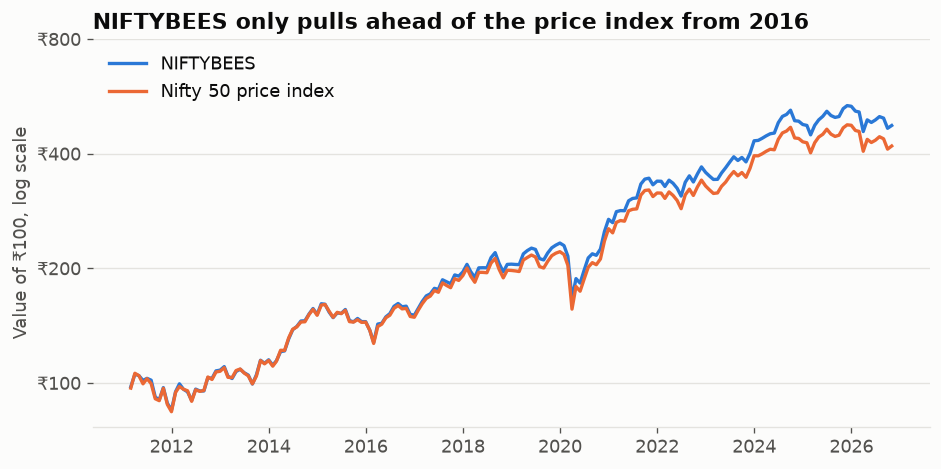

In [5]:
market = data.returns[[config.market_proxy, config.price_index]]
growth = 100 * (1 + market).cumprod()
gap = (market[config.market_proxy] - market[config.price_index])
print(f"Average return gap: {gap.mean() * 12:.2%} a year; tracking difference {gap.std() * 12 ** .5:.2%}")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(growth.index, growth[config.market_proxy], color=SERIES_1, label="NIFTYBEES")
ax.plot(growth.index, growth[config.price_index], color=SERIES_2, label="Nifty 50 price index")
ax.set_yscale("log")
ticks = [100, 200, 400, 800]
ax.set_yticks(ticks, [f"₹{t}" for t in ticks])
ax.minorticks_off()
ax.set_title("NIFTYBEES only pulls ahead of the price index from 2016")
ax.set_ylabel("Value of ₹100, log scale")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "00_market_proxy.png")
plt.show()

## 4. Risk-free rate

IIMA derives its monthly RF from RBI 91-day T-bill yields but stops at December 2025. RBI's Weekly
Statistical Supplement fills the months after that. Over 2025, where both exist, the two can be
compared directly.

Overlap: 13 months, mean annual gap 0.015%, largest monthly gap 0.66% annualized


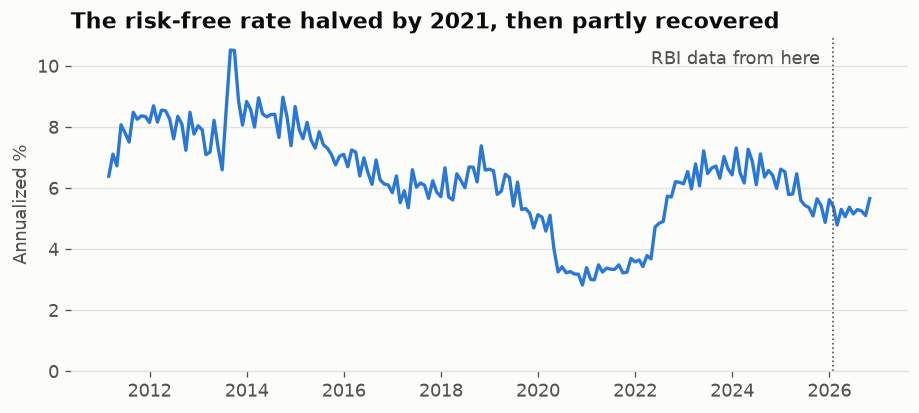

In [6]:
from pmo import returns as ret

weekly = pd.read_parquet(ROOT / "data" / "raw" / "rbi_tbill_weekly.parquet")["tbill_91d"]
rbi = ret.yield_to_monthly_return(weekly)
iima = pd.read_parquet(ROOT / "data" / "raw" / "iima_factors.parquet")["RF"]
overlap = pd.concat([iima.rename("iima"), rbi.rename("rbi")], axis=1).dropna()
print(f"Overlap: {len(overlap)} months, mean annual gap {(overlap.iima - overlap.rbi).mean() * 12:.3%}, "
      f"largest monthly gap {(overlap.iima - overlap.rbi).abs().max() * 12:.2%} annualized")

annual = data.risk_free["rf"] * 12
splice = data.risk_free.index[data.risk_free["source"] == "RBI WSS"].min()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(annual.index, annual * 100, color=SERIES_1)
ax.axvline(splice, color=MUTED, linewidth=1, linestyle=":")
ax.annotate("RBI data from here", (splice, annual.max() * 100), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="top", color=MUTED)
ax.set_title("The risk-free rate halved by 2021, then partly recovered")
ax.set_ylabel("Annualized %")
ax.set_ylim(0)
fig.savefig(FIGURES / "00_risk_free.png")
plt.show()

## 5. Factors

`MKT_RF` is IIMA's market factor, a broad market that is wider than the Nifty 50. Its definition
was not confirmed in IIMA's FAQ, so this cell tests whether it is an excess return. If it is,
adding RF should give a total market return close to NIFTYBEES.
Factors end at December 2025, so regressions that use them cannot reach the end of the holdout.

In [7]:
joined = pd.concat([data.factors, data.risk_free["rf"], data.returns[config.market_proxy]],
                   axis=1).dropna()
total = joined["MKT_RF"] + joined["rf"]
print(f"Annual mean: MKT_RF {joined.MKT_RF.mean() * 12:.1%}, MKT_RF + RF {total.mean() * 12:.1%}, "
      f"NIFTYBEES {joined[config.market_proxy].mean() * 12:.1%}")
print(f"Correlation with NIFTYBEES: {total.corr(joined[config.market_proxy]):.3f}")
pd.DataFrame({"ann_mean": data.factors.mean() * 12,
              "ann_volatility": data.factors.std() * np.sqrt(12)}).round(3)

Annual mean: MKT_RF 7.6%, MKT_RF + RF 13.9%, NIFTYBEES 12.5%
Correlation with NIFTYBEES: 0.925


,ann_mean,ann_volatility
SMB,0.005,0.141
HML,0.075,0.170
WML,0.143,0.168
MKT_RF,0.076,0.158


## 6. Estimation and holdout split

Optimization in Stages 1 to 9 uses only the estimation months. The holdout stays untouched until
the Stage 10 backtest.

In [8]:
split = data.periods.groupby(data.periods).agg(
    months="size",
    start=lambda s: s.index.min().date(),
    end=lambda s: s.index.max().date(),
)
split

,months,start,end
period,,,
estimation,153,2011-02-28,2023-10-31
holdout,36,2023-11-30,2026-10-31
